In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("../../data/processed/cleaned/parse_legal_cases.csv")

In [4]:


pd.set_option('display.max_colwidth', None)
print(df['opinion_text'].head(10))


0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

## SEMANTIC APPROACH

### DECISION PREPROCESSING

In [6]:

import re

def extract_all_disposition_lines(text, min_length=40):
    if not isinstance(text, str):
        return []

    sentences = re.split(r'(?<=[\.\?\!])\s+', text.strip())
    
    result = []
    buffer = ''
    for sentence in sentences:
        buffer += ' ' + sentence.strip()
        if len(buffer.strip()) >= min_length:
            if re.search(r'\b(affirm|determine|sentence|reverse|remand|dismiss|vacate|deny|conclude|find|hold|we|We|court|CONCLUSION|Concluion)\b', buffer, re.IGNORECASE):
                result.append(buffer.strip())
            buffer = ''  # Завжди скидаємо після перевірки

    return result

def get_last_sentences(text, s=10,e =1):
    if not isinstance(text, str):
        return ''
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return ' '.join(sentences[-s:-e])


# Створимо нову колонку з витягнутими рішеннями
df['opinion_text_clean'] = df['opinion_text'].str.replace('\n', ' ', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip()

# 🔹 Витягнути речення з рішеннями
df['decision_lines'] = df['opinion_text_clean'].apply(lambda x: extract_all_disposition_lines(x, min_length=50))

# 🔹 Об'єднати в один рядок (за бажанням)
df['decision_lines_joined'] = df['decision_lines'].apply(lambda lines: ' '.join(lines) if lines else None)
df['decision_end'] = df['decision_lines'].apply(lambda lines: ' '.join(lines[-5:]) if lines else None)

# df['decision_last_sentences'] = df['opinion_text_clean'].apply(
#     lambda x: extract_all_disposition_lines(get_last_sentences(x, n=30), min_length=50)
# )
df['decision_last_sentences'] = df['opinion_text_clean'].apply(
    lambda x: get_last_sentences(x, s=50,e =40)
)
df['final_decision'] = df.apply(
    lambda row: row['decision_end'] if row['decision_end'] else row['decision_last_sentences'],
    axis=1
)


In [61]:
decisions = df[['decision_end','final_decision']]
print(decisions[decisions["decision_end"].isna()])


      decision_end final_decision
40            None               
119           None               
122           None               
130           None               
218           None               
...            ...            ...
29145         None               
29154         None               
29159         None               
29176         None               
29237         None               

[972 rows x 2 columns]


In [66]:
decisions = df[['decision_end', 'decision_last_sentences', 'final_decision']]

# Показати лише ті рядки, де не спрацювали обидва
print(decisions[
    decisions['decision_end'].isna() &
    decisions['decision_last_sentences']
])


      decision_end  \
247           None   
697           None   
808           None   
935           None   
1549          None   
...            ...   
27682         None   
27691         None   
27692         None   
27695         None   
27959         None   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

### DECISION EMBEDDING

In [12]:
from huggingface_hub import list_models

models = list_models(search="legal spanish")
for m in models:
    print(m.modelId)


mrm8488/legalectra-base-spanish
mrm8488/legalectra-small-spanish
Evelyn18/legalectra-base-spanish-finetuned-squad
Evelyn18/legalectra-small-spanish-becasv3-1
Evelyn18/legalectra-small-spanish-becasv3-2
Evelyn18/legalectra-small-spanish-becasv3-3
Evelyn18/legalectra-small-spanish-becasv3-4
Evelyn18/legalectra-small-spanish-becasv3-5
Evelyn18/legalectra-small-spanish-becasv3-6
Narrativa/legal-longformer-base-4096-spanish
mrm8488/legal-longformer-base-8192-spanish
joelniklaus/legal-spanish-roberta-base
joelniklaus/legal-spanish-roberta-large
clibrain/legal-longformer-base-8192-spanish
Ramitha/spanish-legal-10p-3e
Ramitha/spanish-legal-1p-5e
agomez302/spanish-legal-dates-ner


In [14]:
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm

# 1. Моделі
model_en_name = "nlpaueb/legal-bert-base-uncased"       # LegalBERT англійська
model_es_name = "joelniklaus/legal-spanish-roberta-base"                # Legal іспанська

# 2. Завантажити моделі та токенізатори
tokenizer_en = AutoTokenizer.from_pretrained(model_en_name)
model_en = AutoModel.from_pretrained(model_en_name)

tokenizer_es = AutoTokenizer.from_pretrained(model_es_name)
model_es = AutoModel.from_pretrained(model_es_name)

# 3. Функція для отримання CLS embedding
def get_cls_embedding(text, tokenizer, model, device='cpu'):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    # Використовуємо [CLS] токен як вектор
    return outputs.last_hidden_state[:, 0, :].squeeze().cpu()

# 4. Розділити дані
df_en = df[df['decision_end'].notna()].copy()
df_es = df[df['decision_end'].isna()].copy()

# 5. Отримати ембеддинги
tqdm.pandas()

df_en['embedding'] = df_en['final_decision'].progress_apply(lambda x: get_cls_embedding(x, tokenizer_en, model_en))
df_es['embedding'] = df_es['final_decision'].progress_apply(lambda x: get_cls_embedding(x, tokenizer_es, model_es))

# 6. Об’єднати назад
df_combined = pd.concat([df_en, df_es]).sort_index().reset_index(drop=True)



Some weights of RobertaModel were not initialized from the model checkpoint at joelniklaus/legal-spanish-roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
100%|██████████| 972/972 [00:51<00:00, 18.87it/s]


In [19]:
import os
df_combined['embedding'] = df_combined['embedding'].apply(lambda x: x.tolist() if torch.is_tensor(x) else x)



output_dir = "../../data/processed/embedded"
os.makedirs(output_dir, exist_ok=True)

df_combined.to_csv(f"{output_dir}/decision_embedded.csv", index=False)


### Кластеризація


In [3]:
from tqdm import tqdm
import ast
import numpy as np
import umap.umap_ as umap
import pandas as pd
import hdbscan

# Завантаження
df = pd.read_csv("../../data/processed/embedded/decision_embedded.csv")

# Відновлення embeddings зі списків (вони збережені як текстові рядки)
df['embedding'] = df['embedding'].apply(ast.literal_eval)


# Перетворити список embeddings у матрицю
X = np.vstack(df['embedding'].values)


reducer = umap.UMAP(n_neighbors = 100, n_components=5, random_state=42,verbose=True, low_memory=True)
X_umap = reducer.fit_transform(X)

with tqdm(total=1, desc="HDBSCAN Clustering") as pbar:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=10, prediction_data=True)
    clusters = clusterer.fit_predict(X_umap)
    pbar.update(1)

# Додай кластери до DataFrame
df['cluster'] = clusters



/opt/anaconda3/envs/myenv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


UMAP(n_components=5, n_jobs=1, n_neighbors=100, random_state=42, verbose=True)
Tue Sep  9 00:23:02 2025 Construct fuzzy simplicial set
Tue Sep  9 00:23:02 2025 Finding Nearest Neighbors
Tue Sep  9 00:23:02 2025 Building RP forest with 14 trees
Tue Sep  9 00:23:07 2025 NN descent for 15 iterations
	 1  /  15
	 2  /  15
	 3  /  15
	Stopping threshold met -- exiting after 3 iterations
Tue Sep  9 00:24:21 2025 Finished Nearest Neighbor Search
Tue Sep  9 00:24:24 2025 Construct embedding


Epochs completed:   2%| ▏          3/200 [00:00]

	completed  0  /  200 epochs


Epochs completed:  11%| █          22/200 [00:04]

...

Epochs completed:  90%| █████████  181/200 [00:40]

	completed  180  /  200 epochs


Epochs completed: 100%| ██████████ 200/200 [00:45]


Tue Sep  9 00:25:14 2025 Finished embedding


HDBSCAN Clustering:   0%|          | 0/1 [00:00<?, ?it/s]/opt/anaconda3/envs/myenv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
HDBSCAN Clustering: 100%|██████████| 1/1 [00:03<00:00,  3.31s/it]


In [4]:
import pandas as pd
df = pd.read_csv("../../data/processed/embedded/clustered_decisions.csv")

In [5]:
print(df['cluster'].nunique()) 

218


In [11]:
top_cluster = df['cluster'].value_counts().idxmax()
df[df['cluster'] == top_cluster]['final_decision'].sample(5).tolist()


['In finding the cancellation of the FARO valid here, we start from the premise that, as a general matter, with respect to the removal of a noncitizen, "[a]t each stage the Executive has discretion to abandon the endeavor . Xu does contend that the cancellation of her FARO in her case was "unfavorable," given that the DHS purported to cancel it after she had filed her petition for review of it in our Court. And, finally, the government has further represented that "the DHS has agreed not to contest the merits of her grant of CAT protection absent changed circumstances in China." We therefore are not persuaded by Xu\'s arguments for holding that the DHS did not validly cancel her FARO, such that no "final order of removal" is before us. 2017) (exercising jurisdiction over a petition for review of a FARO and declining to find that FARO cancelled where the government had already removed the noncitizen pursuant to it). 4In Xu\'s briefing in opposition to the government\'s motion to dismiss

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


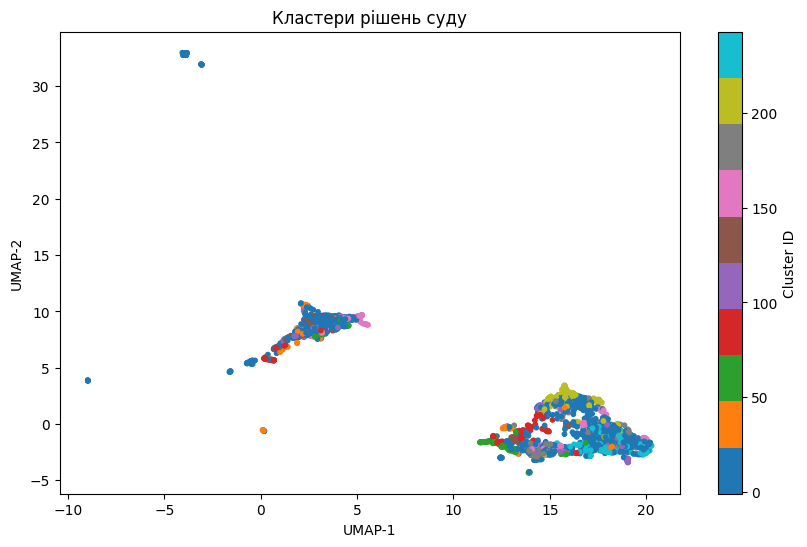

In [10]:
# from tqdm import tqdm
import ast
import numpy as np
import umap.umap_ as umap
import pandas as pd
import hdbscan
import matplotlib.pyplot as plt


# Перетвори рядок у список чисел
df['embedding'] = df['embedding'].apply(ast.literal_eval)

X = np.vstack(df['embedding'].values)

# Якщо хочеш візуалізацію в 2D, перезменшимо:
reducer = umap.UMAP(n_components=2, random_state=42)
X_vis = reducer.fit_transform(X)


plt.figure(figsize=(10, 6))
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=df['cluster'], cmap='tab10', s=10)
plt.title("Кластери рішень суду")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.colorbar(label="Cluster ID")
plt.show()


### Topic modelling


In [13]:
import pandas as pd
from bertopic import BERTopic
df = pd.read_csv("../../data/processed/embedded/clustered_decisions.csv")
# Список унікальних кластерів
unique_clusters = df['cluster'].dropna().unique()

# Порожні колонки для результатів
df['topic_id'] = None
df['topic_keywords'] = None

# Проходження по кожному кластеру
for cluster in unique_clusters:
    print(f"🔍 Обробка кластера {cluster}...")


   # Витягти тексти цього кластера, прибрати NaN і привести до рядка
    cluster_mask = df['cluster'] == cluster
    texts = df.loc[cluster_mask, 'final_decision'].dropna().astype(str).tolist()

    
    # Пропустити, якщо замало текстів
    if len(texts) < 5:
        print(f"⚠️ Кластер {cluster} містить занадто мало текстів: {len(texts)} — пропущено.")
        continue

    # Створити BERTopic
    topic_model = BERTopic(language="multilingual")
    topics, probs = topic_model.fit_transform(texts)

    # Присвоїти topic_id
    df.loc[cluster_mask, 'topic_id'] = topics

    # Функція для назв тем
    def topic_name(topic_id):
        if topic_id == -1:
            return "Other"
        return ", ".join([word for word, _ in topic_model.get_topic(topic_id)])

    # Присвоїти ключові слова тем
    df.loc[cluster_mask, 'topic_keywords'] = df.loc[cluster_mask, 'topic_id'].apply(topic_name)

print("✅ Готово!")


🔍 Обробка кластера 200...
🔍 Обробка кластера 88...
🔍 Обробка кластера -1...
🔍 Обробка кластера 242...
🔍 Обробка кластера 83...
🔍 Обробка кластера 68...
🔍 Обробка кластера 117...
🔍 Обробка кластера 181...
🔍 Обробка кластера 22...
🔍 Обробка кластера 27...
🔍 Обробка кластера 10...
🔍 Обробка кластера 97...
🔍 Обробка кластера 139...
🔍 Обробка кластера 99...
🔍 Обробка кластера 79...
🔍 Обробка кластера 203...
🔍 Обробка кластера 157...
🔍 Обробка кластера 0...
⚠️ Кластер 0 містить занадто мало текстів: 1 — пропущено.
🔍 Обробка кластера 108...
🔍 Обробка кластера 243...
🔍 Обробка кластера 41...
🔍 Обробка кластера 111...
🔍 Обробка кластера 231...
🔍 Обробка кластера 218...
🔍 Обробка кластера 152...
🔍 Обробка кластера 163...
🔍 Обробка кластера 212...
🔍 Обробка кластера 113...
🔍 Обробка кластера 209...
🔍 Обробка кластера 96...
🔍 Обробка кластера 9...
🔍 Обробка кластера 81...
🔍 Обробка кластера 190...
🔍 Обробка кластера 183...
🔍 Обробка кластера 186...
🔍 Обробка кластера 12...
🔍 Обробка кластера 227..

In [15]:
# Зберегти весь DataFrame у файл
df.to_csv("../../data/processed/embedded/df_with_clusters_and_topics.csv", index=False)


### relevant tables creation

In [21]:
# Всі записи, де вже є визначена тема
print(df[df['topic_id']!=-1][['cluster', 'topic_id', 'topic_keywords', 'final_decision']])




       cluster topic_id                                     topic_keywords  \
1           88        0  of, florida, the, court, appeal, state, for, c...   
3           -1      100  strickland, dykes, counsel, assistance, stimso...   
4           -1       26  louisiana, parish, supervisory, versus, writs,...   
6          242        0    the, of, court, to, we, that, in, and, for, not   
7           -1        4  remand, judgment, trial, summary, reverse, llc...   
...        ...      ...                                                ...   
29246       -1       32  alj, claimant, injury, board, wcj, compensable...   
29247      203        0    the, of, to, that, in, court, and, is, not, for   
29249       -1       57  georgia, atlanta, extract, hereto, above, minu...   
29250       -1       94  tennessee, tenn, exemption, procedure, duncan,...   
29251       -1        2  00, fees, attorney, costs, award, amount, fee,...   

                                          final_decision  
1   

In [22]:
all_keywords_str = " ".join(df["topic_keywords"].dropna().tolist())
all_keywords_list = [word.strip() for word in all_keywords_str.split(",")]
unique_keywords = sorted(set(all_keywords_list))
print(unique_keywords)


['', '01', '01 00', '01 Other Other Other Other Other expires', '01 Other Other of', '01 Other Other the', '01 Other mandamus', '01 Other of', '01 Other ohio', '01 Other sentence', '01 Other supreme', '01 Other texas', '01 Other the', '01 _____________________________', '01 __________________________________________________________________', '01 compensation', '01 cplr', '01 florida', '01 mother', '01 of', '01 remand', '01 reporter', '01 rules', '01 sentence', '01 statute', '01 the', '01 unanimously', '04', '05', '08', '0ÿ Other Other court', '0ÿ Other Other mother', '0ÿ Other constitutes', '0ÿ Other mandamus', '0ÿ Other policy', '0ÿ mandamus', '0ÿ murder', '0ÿ of', '0ÿ strickland', '0ÿ the', '110', '1105', '1127', '11th', '120', '1207', '12277', '1240', '13', '13869', '1400 Other Other Other Other Other Other mandamus', '1400 Other Other the', '1400 Other nebraska', '1400 Other of', '1400 Other the', '1400 court', '1400 johnson', '1400 practiced', '1400 the', '1400 williams', '141', '

In [26]:
import re

# Твій список
raw_list = unique_keywords 

# Стоп-слова
stop_words = {'the', 'other', 'and', 'of', '00', '01'}

cleaned = []
for item in raw_list:
    # 1. Пропустити порожні строки або короткі
    if not item.strip() or len(item.strip()) < 3:
        continue
    
    # 2. Видалити зайві пробіли
    item = item.strip()
    
    # 3. Прибрати "Other Other", "__", цифри
    item = re.sub(r'\bOther\b', '', item, flags=re.IGNORECASE)
    item = re.sub(r'[_\d]+', '', item)
    
    # 4. Прибрати стоп-слова
    words = item.lower().split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    
    cleaned_item = ' '.join(words)
    
    if cleaned_item and cleaned_item not in cleaned:
        cleaned.append(cleaned_item)

# Результат
print(cleaned)


['expires', 'mandamus', 'ohio', 'sentence', 'supreme', 'texas', 'compensation', 'cplr', 'florida', 'mother', 'remand', 'reporter', 'rules', 'statute', 'unanimously', 'court', 'constitutes', 'policy', 'murder', 'strickland', 'nebraska', 'johnson', 'practiced', 'williams', 'district', 'pennsylvania', 'sexual', 'observance', 'search', 'usca', 'alj', 'appeal', 'commonwealth', 'error', 'having', 'number', 'writ', 'applicant', 'arkansas', 'bannister', 'dismiss', 'georgia', 'paso', 'people', 'respondent', 'triana', 'trotter', 'vaccine', 'arbitration', 'certiorari', 'clerk', 'discipline', 'environmental', 'final', 'flynn', 'force', 'fraudulent', 'immunity', 'iowa', 'laches', 'lozada', 'notice', 'plaintiff', 'property', 'sex', 'taco', 'venue', 'vitela', 'west', 'wever', 'maryland', 'petitioner', 'evidence', 'habeas', 'dallas', 'pendens', 'tokes', 'value', 'bar', 'columbia', 'nevada', 'order', 'pcra', 'motionfiled', 'viewing', 'extension', 'party', 'antonio', 'california', 'brown', 'interlocutor

In [28]:
import pandas as pd
legal_procedure_keywords = [
    "petition", "appeal", "motion", "remand", "dismiss", "reversed", "affirmed", "writ",
    "certiorari", "summary", "interlocutory", "stipulation", "jurisdiction", "mandamus",
    "trial", "sentence", "conviction", "probation", "testimony", "evidence", "error",
    "restitution", "judgment", "opinion", "order", "rehearing", "appellate", "dismissal",
    "disciplinary", "precedent", "plea", "decree", "fee"
]


# Якщо topic_keywords — рядок зі словами через кому
df['topic_keywords_list'] = df['topic_keywords'].fillna('').apply(lambda x: [kw.strip().lower() for kw in x.split(',')])

# Для кожного ключового слова — створити окрему колонку
for keyword in legal_procedure_keywords:
    col_name = f"kw_{keyword}"
    df[col_name] = df['topic_keywords_list'].apply(lambda kws: int(keyword in kws))


In [31]:
# 1. Вибрати всі колонки з kw_
keyword_cols = [col for col in df.columns if col.startswith('kw_')]

# 2. Групувати по ШТАТУ та ТИПУ СПРАВИ
grouped = df.groupby(['case_type_inferred', 'court_jurisdiction'])[keyword_cols].mean() * 100

# 3. Округлити до 1 знаку після коми
filtered_cols = [col for col in grouped.columns if grouped[col].max() >= 5]
grouped = grouped[filtered_cols]
grouped = grouped[(grouped[filtered_cols] != 0).any(axis=1)]
# 5. Повернути індекси в колонки
grouped = grouped.reset_index()

# 6. Відсортувати
grouped_sorted = grouped.sort_values(by=['case_type_inferred', 'court_jurisdiction'])

# 7. Показати
display(grouped_sorted)



,case_type_inferred,court_jurisdiction,kw_petition,kw_appeal,kw_motion,kw_remand,kw_dismiss,kw_writ,kw_certiorari,kw_summary,...,kw_error,kw_restitution,kw_judgment,kw_opinion,kw_order,kw_rehearing,kw_dismissal,kw_disciplinary,kw_plea,kw_fee
0,Administrative Case,"Arkansas, AR",0.000000,0.000000,0.000000,6.250000,0.000000,0.000000,0.000000,6.250000,...,0.0,0.0,6.250000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000
1,Administrative Case,"California, CA",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,3.333333,0.000000,0.00000,0.000000,0.000000,0.0,0.000000
2,Administrative Case,"Connecticut, CT",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,16.666667
3,Administrative Case,"Delaware, DE",0.000000,0.806452,4.838710,0.806452,3.225806,0.000000,0.000000,0.806452,...,0.0,0.0,3.225806,0.000000,0.000000,0.00000,1.612903,0.000000,0.0,2.419355
4,Administrative Case,"Florida, FL",0.414938,34.854772,0.829876,1.244813,0.000000,0.000000,0.000000,1.244813,...,0.0,0.0,1.244813,2.904564,0.414938,3.73444,0.000000,0.000000,0.0,2.904564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,Other,"USA, Federal",8.571429,20.952381,2.857143,1.904762,0.952381,6.666667,0.952381,1.904762,...,0.0,0.0,1.904762,0.000000,4.761905,0.00000,0.952381,0.952381,0.0,0.000000
147,Other,"Utah, UT",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000
148,Other,"Virginia, VA",0.000000,12.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000
149,Other,"Washington, WA",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000


In [32]:
grouped.to_csv("../../data/processed/legal_keywords_summary_by_state_and_type.csv", index=False)


## LAW REFERENCE APPROACH

In [85]:
df = pd.read_csv("../../data/processed/cleaned/parse_legal_cases.csv")





# Створимо нову колонку з витягнутими рішеннями
df['opinion_text_clean'] = df['opinion_text'].str.replace('\n', ' ', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip()





KeyboardInterrupt: 

In [84]:


import re
df['opinion_text_clean'] = df['opinion_text'].str.replace('\n', ' ', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip()

def extract_law_references(text):
    if not isinstance(text, str):
        return []  # Якщо не рядок — повертаємо порожній список

    pattern = r"""
        (?:Section\s?\d+[A-Za-z0-9()\-]*) |               # Section 1983
        (?:§\s?\d+[A-Za-z0-9()\-]*) |                     # § 245(a)(1)
        (?:Title\s?[IVXLCDM]+) |                          # Title VII
        (?:U(?:\.|\s)?S(?:\.|\s)?\.?\s+Code) |            # U.S. Code / U S Code
        (?:United\s+States\s+Code) |                      # United States Code
        (?:[A-Z][a-z]+(?:\s+Code))                        # Penal Code / Civil Code
    """

    matches = re.findall(pattern, text, flags=re.IGNORECASE | re.VERBOSE)
    return list(set(m.strip() for m in matches))




df['references'] = df['opinion_text_clean'].apply(extract_law_references)


KeyError: 'opinion_text_clean'

In [41]:
print(df[["case_name",'case_type_inferred', 'court_jurisdiction','references']].head(20))

                                            case_name   case_type_inferred  \
0                Pool v. Continental Casualty Company           Civil Case   
1   Ester Lelchook v.Société Générale de Banque au...                Other   
2            in Re Commitment of V.S. A/K/A V.S., Jr.                Other   
3   Personal Restraint Petition Of: Robert Recco M...                Other   
4   Steven A. Marks and Erin L. Marks v. United Pr...           Civil Case   
5                   Ex Parte: John Nathaniel Thompson                Other   
6                      Gasbarre Products v. Smith, S.           Civil Case   
7                    Empire Health Foundation v. Azar           Civil Case   
8   MAX TAFEL SELMAN v. PROGRESSIVE AMERICAN INSUR...           Civil Case   
9          In Re: Discipline Of Thomas C. Michaelides                Other   
10  Martie Y. Garcia-Vela, Individually and D/B/A ...           Civil Case   
11                                  State v. Lisenbee  Criminal 

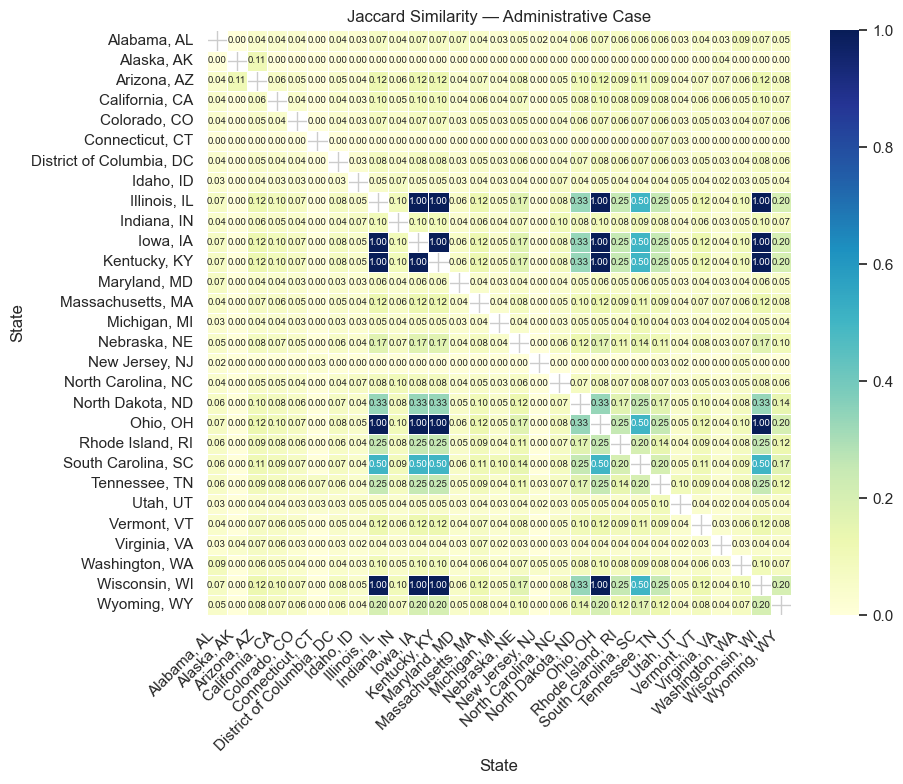

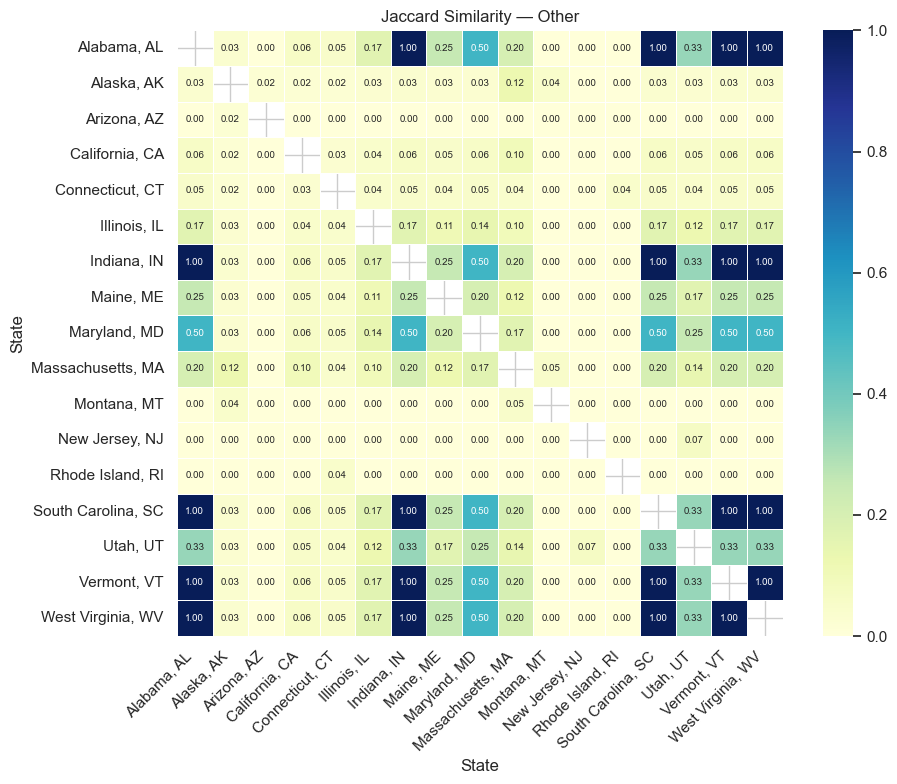

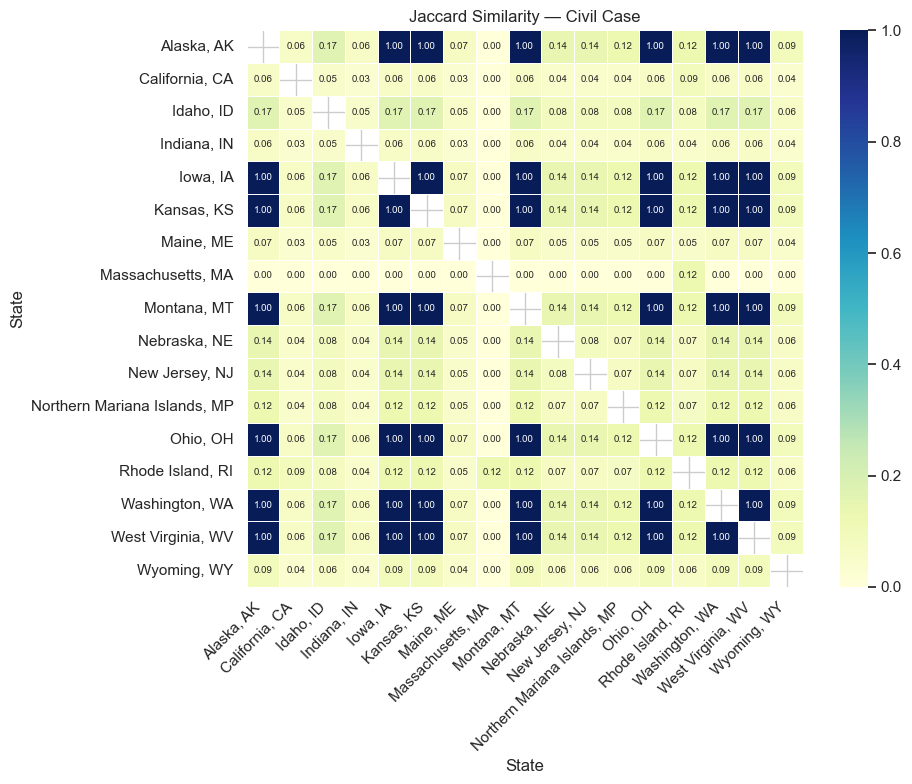

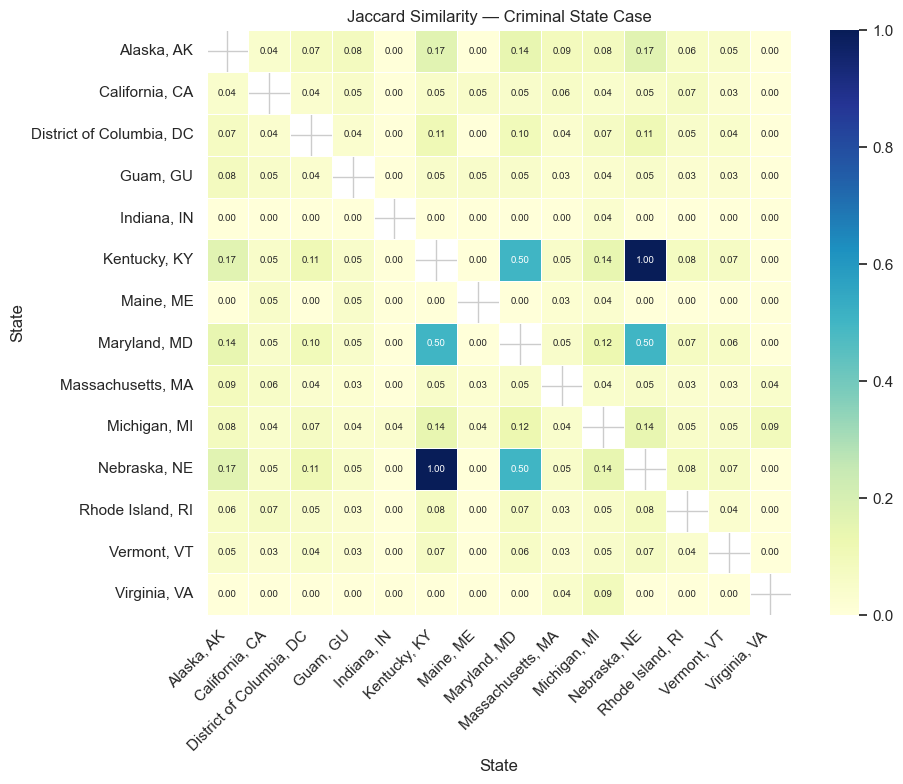

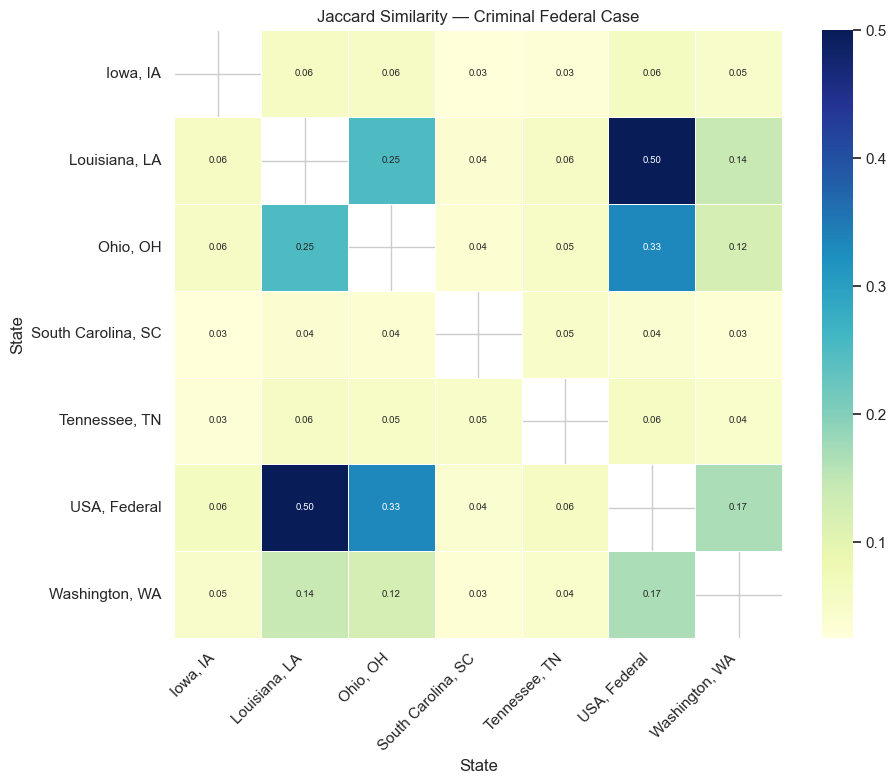

In [119]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.metrics import jaccard_score
from sklearn.preprocessing import MultiLabelBinarizer
from itertools import combinations

# 🧹 1. ОЧИСТКА: формування law_set
df['law_set'] = df['references'].apply(lambda x: frozenset(x) if isinstance(x, list) else frozenset())

# 📊 2. ВИБІР ТОП-КОМБІНАЦІЙ ЗАКОНІВ ДЛЯ КОЖНОГО ШТАТУ ТА ТИПУ СПРАВИ
grouped = df.groupby(['court_jurisdiction', 'case_type_inferred'])['law_set']
top_combinations_by_group = {}

for (state, case_type), group_laws in grouped:
    combination_counts = Counter(group_laws)
    top_combo = combination_counts.most_common(1)
    top_combinations_by_group[(state, case_type)] = top_combo

# 📄 3. Створення df_combos
records = []
for (state, case_type), combos in top_combinations_by_group.items():
    for combo, count in combos:
        records.append({
            'state': state,
            'case_type': case_type,
            'laws': ', '.join(sorted(list(combo))),
            'law_list': sorted(list(combo)),
            'count': count
        })
df_combos = pd.DataFrame(records)

# 🧽 4. Видалити порожні або пусті записи
df_combos = df_combos[df_combos['law_list'].apply(lambda x: len(x) > 0)].reset_index(drop=True)

# 📐 5. ОБЧИСЛЕННЯ ПАРНОЇ СХОЖОСТІ ЗА JACCARD ДЛЯ КОЖНОГО ТИПУ СПРАВИ
similarity_records = []
case_types = df_combos['case_type'].unique()

for case_type in case_types:
    subset = df_combos[df_combos['case_type'] == case_type].copy()
    if len(subset) < 2:
        continue

    mlb = MultiLabelBinarizer()
    law_matrix = mlb.fit_transform(subset['law_list'])

    indexed_rows = list(subset.iterrows())
    for (idx1, row1), (idx2, row2) in combinations(enumerate(indexed_rows), 2):
        i = idx1
        j = idx2

        row1 = row1[1]
        row2 = row2[1]
        
        state1 = row1['state']
        state2 = row2['state']
        
        laws1 = law_matrix[i]
        laws2 = law_matrix[j]
        
        if laws1.sum() == 0 and laws2.sum() == 0:
            similarity = 1.0
        elif laws1.sum() == 0 or laws2.sum() == 0:
            similarity = 0.0
        else:
            similarity = jaccard_score(laws1, laws2)

        similarity_records.append({
            'case_type': case_type,
            'state_1': state1,
            'state_2': state2,
            'similarity': round(similarity, 3)
        })

df_similarity = pd.DataFrame(similarity_records)

# HEATMAP 
for case_type in df_similarity['case_type'].unique():
    df_case = df_similarity[df_similarity['case_type'] == case_type]

    if df_case.empty:
        continue


        # Створення повної матриці подібності
    pivot = df_case.pivot(index='state_1', columns='state_2', values='similarity')

    # Об'єднати index і columns в повну уніфіковану множину штатів
    states = sorted(set(pivot.index).union(set(pivot.columns)))

    # Повторно створити квадратну матрицю з усіма штатами
    pivot = pivot.reindex(index=states, columns=states)

    # Симетрія: заповнити нижню або верхню частину
    pivot = pivot.combine_first(pivot.T)

    # Заповнити залишки
    pivot = pivot.fillna(0)

    # Видалити повністю нульові рядки/стовпці
    pivot = pivot.loc[(pivot != 0).any(axis=1), (pivot != 0).any(axis=0)]

    # Створення маски для діагоналі
    mask = np.eye(len(pivot), dtype=bool)

    # Візуалізація
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        linewidths=0.5,
        annot_kws={"size": 7},
        mask=mask,
        cbar=True,
        square=True  # 🔑 це вирівнює клітинки в квадрат
    )

    plt.title(f"Jaccard Similarity — {case_type}")
    plt.xlabel("State")
    plt.ylabel("State")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()




In [59]:
df_self = df_similarity[df_similarity['state_1'] == df_similarity['state_2']]
print(df_self[['state_1', 'state_2', 'similarity']].head(10))


Empty DataFrame
Columns: [state_1, state_2, similarity]
Index: []


In [52]:
for (state, case_type), combos in top_combinations_by_group.items():
    print(f"\n📍 {state} — {case_type}")
    for combo, count in combos:
        print(f"  🔗 Laws: {sorted(list(combo))} — 🧮 {count} справ(и)")



📍 Alabama, AL — Administrative Case
  🔗 Laws: ['Section 25', 'Section 8-21B-13', 'Title L', 'title i', 'titled', '§ 1', '§ 8-21B-', '§ 8-21B-1', '§ 8-21B-10', '§ 8-21B-13', '§ 8-21B-4', '§ 8-21B-8(b)', '§ 8-21B-8(c)', '§ 8-21B-8(e)', '§ 8-21B-9'] — 🧮 1 справ(и)

📍 Alabama, AL — Civil Case
  🔗 Laws: [] — 🧮 5 справ(и)

📍 Alabama, AL — Criminal State Case
  🔗 Laws: [] — 🧮 9 справ(и)

📍 Alabama, AL — Other
  🔗 Laws: ['titled'] — 🧮 2 справ(и)

📍 Alaska, AK — Administrative Case
  🔗 Laws: ['Administrative Code', '§ 8'] — 🧮 2 справ(и)

📍 Alaska, AK — Civil Case
  🔗 Laws: ['titled'] — 🧮 1 справ(и)

📍 Alaska, AK — Criminal State Case
  🔗 Laws: ['Section 9', 'the code', 'titled', '§ 10', '§ 23', '§ 80'] — 🧮 1 справ(и)

📍 Alaska, AK — Other
  🔗 Laws: ['Section 10', 'Section 10(a)', 'Section 11', 'Section 6', 'section 10', 'section 10(b)', 'section 11', 'section 16', 'section 5', 'section 6', 'section 7', 'section 8', 'titled', '§ 1', '§ 10', '§ 10(a)', '§ 10(b)', '§ 10301', '§ 10301(b)', '§ 11',

# Succes

In [65]:

import re
df = pd.read_csv("../../data/processed/cleaned/parse_legal_cases.csv")
def extract_all_disposition_lines(text, min_length=40):
    if not isinstance(text, str):
        return []

    sentences = re.split(r'(?<=[\.\?\!])\s+', text.strip())
    
    result = []
    buffer = ''
    for sentence in sentences:
        buffer += ' ' + sentence.strip()
        if len(buffer.strip()) >= min_length:
            if re.search(r'\b(affirm|determine|sentence|reverse|remand|dismiss|vacate|deny|conclude|find|hold|we|We|court|CONCLUSION|Concluion)\b', buffer, re.IGNORECASE):
                result.append(buffer.strip())
            buffer = ''  # Завжди скидаємо після перевірки

    return result

def get_last_sentences(text, s=10,e =1):
    if not isinstance(text, str):
        return ''
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return ' '.join(sentences[-s:-e])


# Створимо нову колонку з витягнутими рішеннями
df['opinion_text_clean'] = df['opinion_text'].str.replace('\n', ' ', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip()

# 🔹 Витягнути речення з рішеннями
df['decision_lines'] = df['opinion_text_clean'].apply(lambda x: extract_all_disposition_lines(x, min_length=50))

# 🔹 Об'єднати в один рядок (за бажанням)
df['decision_lines_joined'] = df['decision_lines'].apply(lambda lines: ' '.join(lines) if lines else None)
df['decision_end'] = df['decision_lines'].apply(lambda lines: ' '.join(lines[-5:]) if lines else None)

# df['decision_last_sentences'] = df['opinion_text_clean'].apply(
#     lambda x: extract_all_disposition_lines(get_last_sentences(x, n=30), min_length=50)
# )
df['decision_last_sentences'] = df['opinion_text_clean'].apply(
    lambda x: get_last_sentences(x, s=50,e =40)
)
df['final_decision'] = df.apply(
    lambda row: row['decision_end'] if row['decision_end'] else row['decision_last_sentences'],
    axis=1
)


In [63]:
!python -m spacy download en_core_web_sm


python(17306) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 6.8 MB/s eta 0:00:00a 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [68]:
from tqdm import tqdm
import spacy
import re

# Завантаження моделі без parser/ner для швидкості
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

success_keywords = ["reverse", "grant", "vacate", "remand", "award", "judgment for the plaintiff"]
fail_keywords = ["affirm", "dismiss", "deny", "judgment for the defendant", "plaintiff take nothing"]

def count_keyword_matches(text, keywords):
    count = 0
    for kw in keywords:
        pattern = r'\b' + re.escape(kw) + r'\b'
        count += len(re.findall(pattern, text))
    return count

# Текстові дані
texts = df['final_decision'].fillna("").tolist()
rates = []

# Додаємо tqdm до nlp.pipe()
for doc in tqdm(nlp.pipe(texts, batch_size=64), total=len(texts), desc="Lemmatizing"):
    lemmatized = " ".join([token.lemma_ for token in doc])
    s_count = count_keyword_matches(lemmatized, success_keywords)
    f_count = count_keyword_matches(lemmatized, fail_keywords)
    total = s_count + f_count
    rate = s_count / total if total > 0 else None
    rates.append(rate)

df['success_rate'] = rates


Lemmatizing: 100%|██████████| 29256/29256 [08:44<00:00, 55.76it/s]


In [69]:
print(df[['success_rate', 'case_type_inferred', 'court_jurisdiction']].head(10))

   success_rate case_type_inferred court_jurisdiction
0      0.333333         Civil Case       USA, Federal
1           NaN              Other       New York, NY
2      0.333333              Other          Texas, TX
3      0.000000              Other     Washington, WA
4           NaN         Civil Case      Louisiana, LA
5      0.000000              Other          Texas, TX
6      0.000000         Civil Case   Pennsylvania, PA
7      1.000000         Civil Case       USA, Federal
8      0.800000         Civil Case        Florida, FL
9      1.000000              Other         Nevada, NV


In [71]:
df_success = df[['success_rate', 'case_type_inferred', 'court_jurisdiction']].dropna()
df_success.to_csv("../../data/processed/states_types_succes_rate.csv", index = False)

In [74]:
import pandas as pd
df_success = pd.read_csv("../../data/processed/states_types_succes_rate.csv")
df_success = (df_success.groupby(['case_type_inferred', 'court_jurisdiction'])['success_rate'].mean() * 100).reset_index()
print(df_success.head(20))

     case_type_inferred        court_jurisdiction  success_rate
0   Administrative Case               Alabama, AL     56.666667
1   Administrative Case                Alaska, AK     83.928571
2   Administrative Case               Arizona, AZ     56.666667
3   Administrative Case              Arkansas, AR     35.512821
4   Administrative Case            California, CA     43.166667
5   Administrative Case              Colorado, CO     60.909091
6   Administrative Case           Connecticut, CT     50.000000
7   Administrative Case              Delaware, DE     39.753599
8   Administrative Case  District of Columbia, DC     33.333333
9   Administrative Case               Florida, FL     64.487270
10  Administrative Case               Georgia, GA     68.553114
11  Administrative Case                 Idaho, ID     59.375000
12  Administrative Case              Illinois, IL     46.884921
13  Administrative Case               Indiana, IN     33.333333
14  Administrative Case                 

<Figure size 1200x600 with 0 Axes>

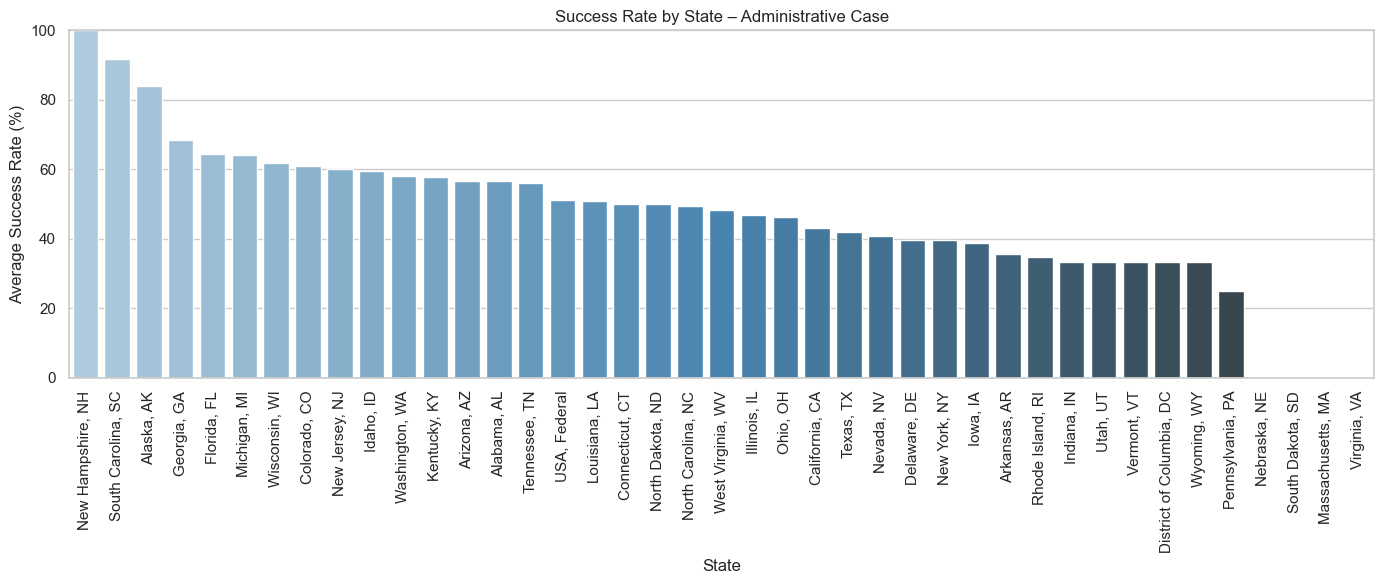

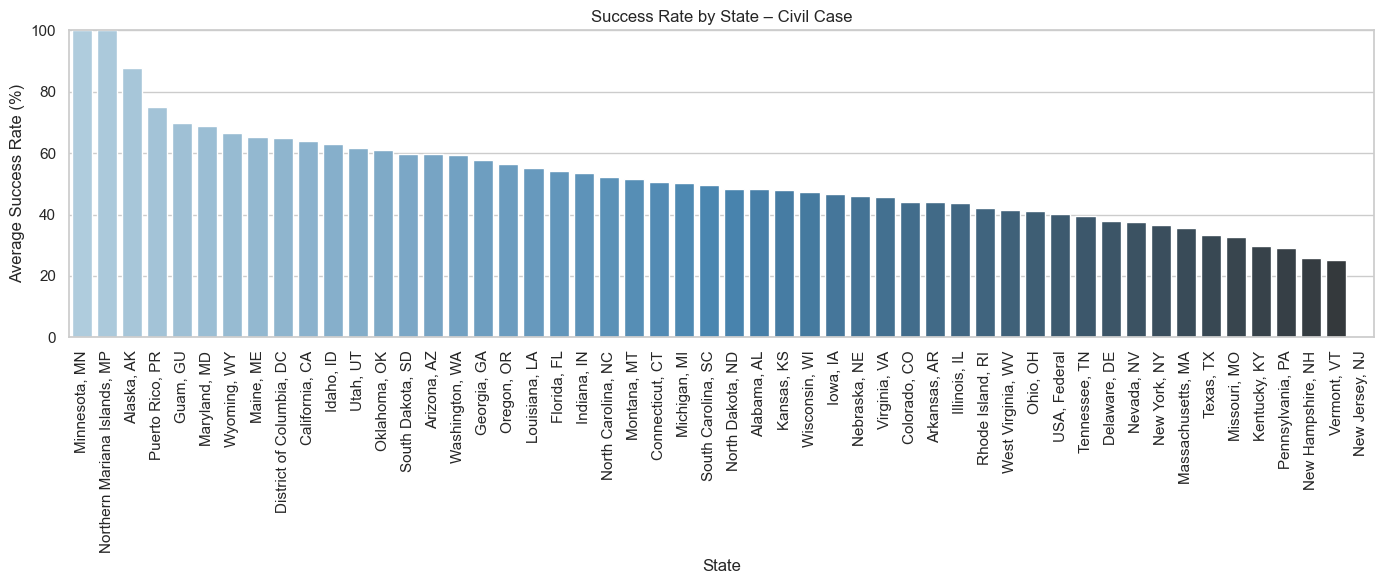

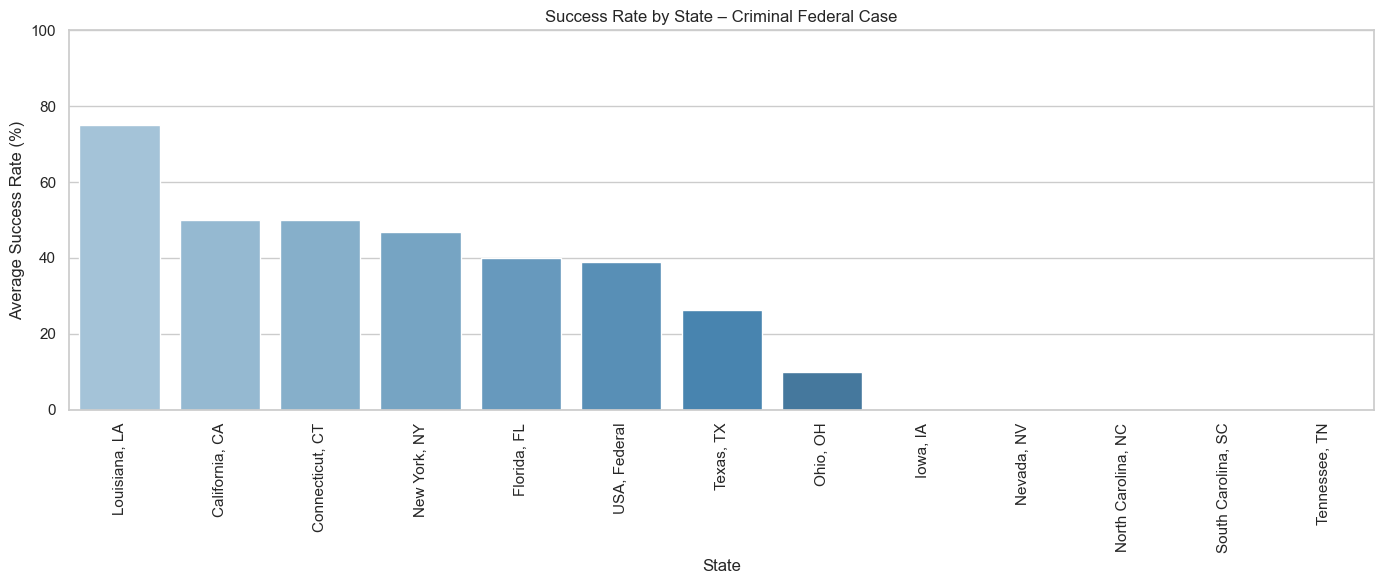

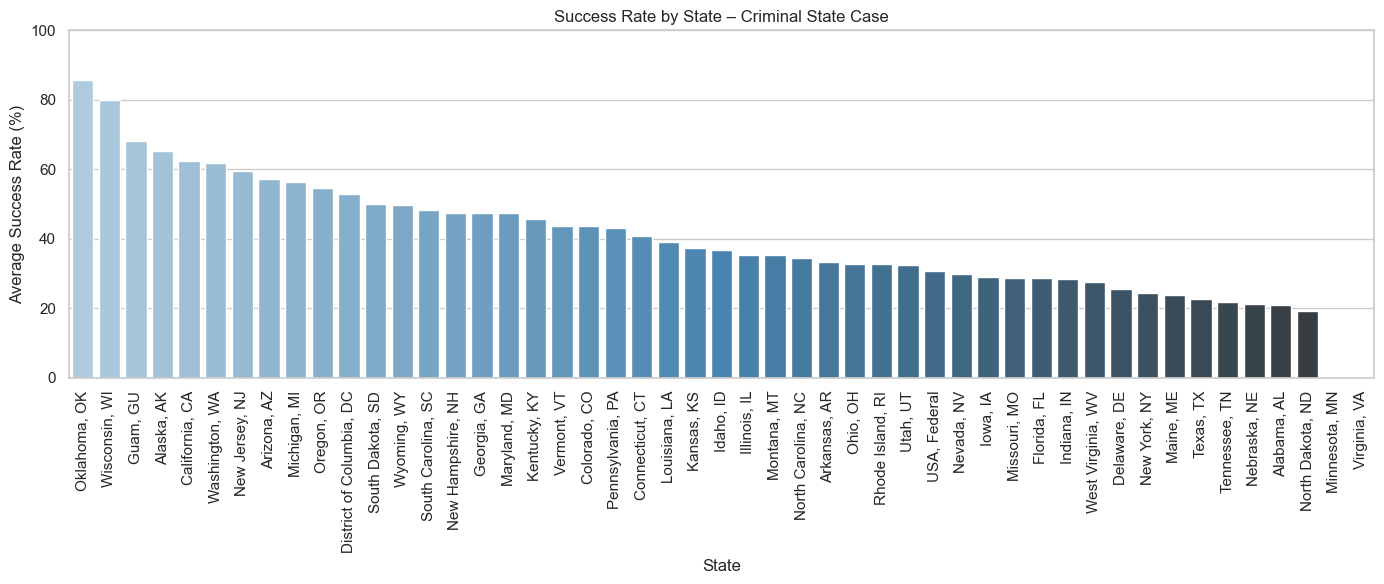

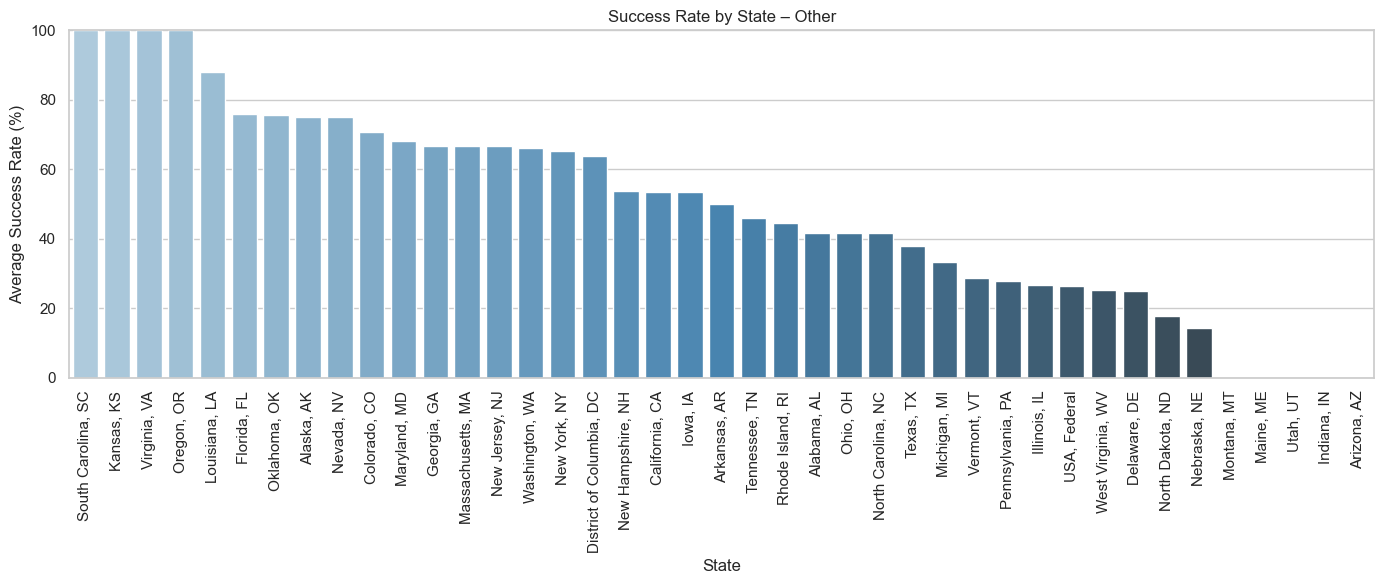

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

# Створимо список унікальних типів справ
case_types = df_success['case_type_inferred'].unique()

# Налаштування стилю графіка
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))

# Побудова графіка для кожного типу
for case_type in case_types:
    subset = df_success[df_success['case_type_inferred'] == case_type]

    plt.figure(figsize=(14, 6))
    subset_sorted = subset.sort_values(by='success_rate', ascending=False)

    sns.barplot(
        data=subset_sorted,
        x='court_jurisdiction',
        y='success_rate',
        palette='Blues_d'
    )

    plt.title(f"Success Rate by State – {case_type}")
    plt.ylabel("Average Success Rate (%)")
    plt.xlabel("State")
    plt.xticks(rotation=90)
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()


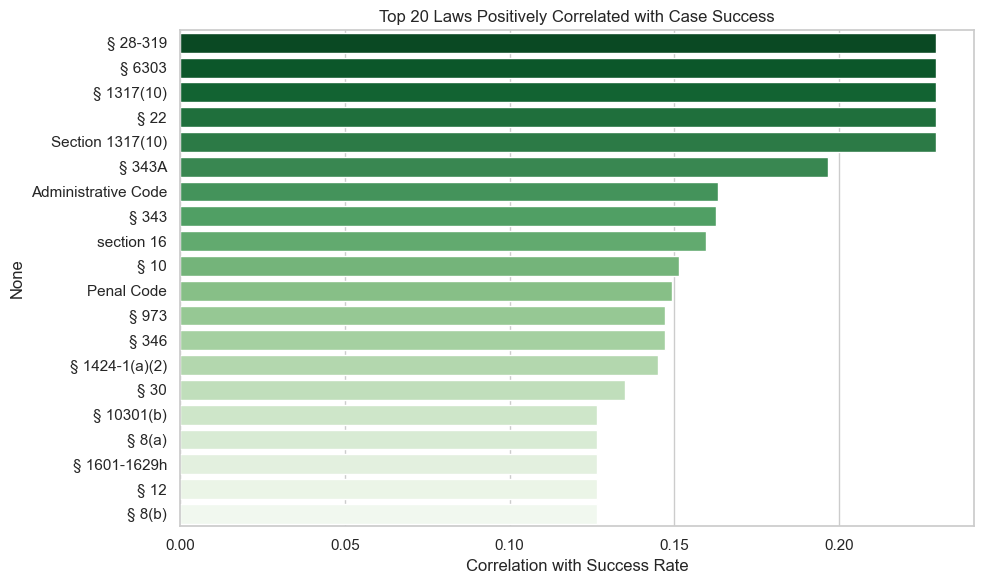

In [88]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer
df = pd.read_csv("../../data/processed/cleaned/parse_legal_cases.csv")
df_success = pd.read_csv("../../data/processed/states_types_succes_rate.csv")
def extract_law_references(text):
    if not isinstance(text, str):
        return []  # Якщо не рядок — повертаємо порожній список

    pattern = r"""
        (?:Section\s?\d+[A-Za-z0-9()\-]*) |               # Section 1983
        (?:§\s?\d+[A-Za-z0-9()\-]*) |                     # § 245(a)(1)
        (?:Title\s?[IVXLCDM]+) |                          # Title VII
        (?:U(?:\.|\s)?S(?:\.|\s)?\.?\s+Code) |            # U.S. Code / U S Code
        (?:United\s+States\s+Code) |                      # United States Code
        (?:[A-Z][a-z]+(?:\s+Code))                        # Penal Code / Civil Code
    """

    matches = re.findall(pattern, text, flags=re.IGNORECASE | re.VERBOSE)
    return list(set(m.strip() for m in matches))

df['opinion_text_clean'] = df['opinion_text'].str.replace('\n', ' ', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip()
df['references'] = df['opinion_text_clean'].apply(extract_law_references)

# ========== 1. Створення law_set ==========
df['law_set'] = df['references'].apply(lambda x: frozenset(x) if isinstance(x, list) else frozenset())

# ========== 2. Топова комбінація законів на групу ==========
grouped = df.groupby(['court_jurisdiction', 'case_type_inferred'])['law_set']
top_combinations_by_group = {}

for (state, case_type), group_laws in grouped:
    combination_counts = Counter(group_laws)
    top_combo = combination_counts.most_common(1)
    top_combinations_by_group[(state, case_type)] = top_combo

# ========== 3. Формування df_combos ==========
records = []
for (state, case_type), combos in top_combinations_by_group.items():
    for combo, count in combos:
        records.append({
            'state': state,
            'case_type': case_type,
            'laws': ', '.join(sorted(list(combo))),
            'law_list': sorted(list(combo)),
            'count': count
        })
df_combos = pd.DataFrame(records)
df_combos = df_combos[df_combos['law_list'].apply(lambda x: len(x) > 0)].reset_index(drop=True)

# ========== 4. Підготовка успішності ==========
df_grouped = df_success.groupby(
    ['court_jurisdiction', 'case_type_inferred']
)['success_rate'].mean().reset_index()

df_grouped = df_grouped.rename(columns={
    'court_jurisdiction': 'state',
    'case_type_inferred': 'case_type',
    'success_rate': 'avg_success_rate'
})

# ========== 5. Об'єднання ==========
df_law_success = pd.merge(df_combos, df_grouped, on=['state', 'case_type'], how='left')

# ========== 6. One-hot encoding для законів ==========
mlb = MultiLabelBinarizer()
law_features = mlb.fit_transform(df_law_success['law_list'])

df_law_features = pd.DataFrame(law_features, columns=mlb.classes_)
df_law_features['avg_success_rate'] = df_law_success['avg_success_rate'].values

# ========== 7. Кореляція ==========
correlations = df_law_features.corr(numeric_only=True)['avg_success_rate'].drop('avg_success_rate')
correlations = correlations.sort_values(ascending=False)

# ========== 8. Візуалізація ТОП-20 позитивно пов'язаних законів ==========
top_laws = correlations.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_laws.values, y=top_laws.index, palette="Greens_r")
plt.xlabel("Correlation with Success Rate")
plt.title("Top 20 Laws Positively Correlated with Case Success")
plt.tight_layout()
plt.show()


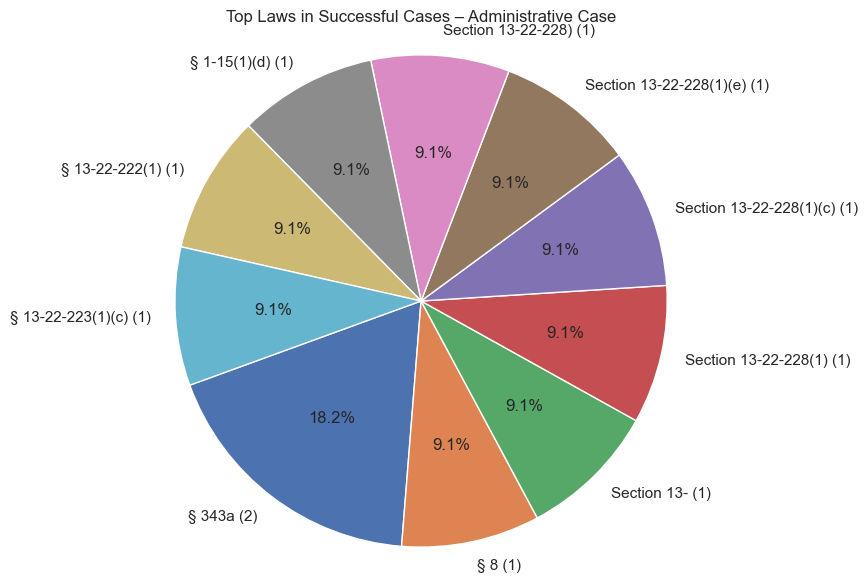

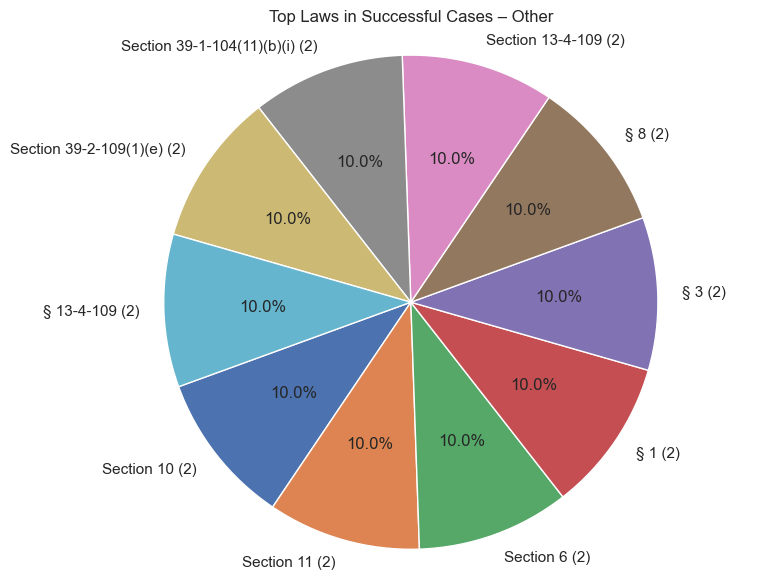

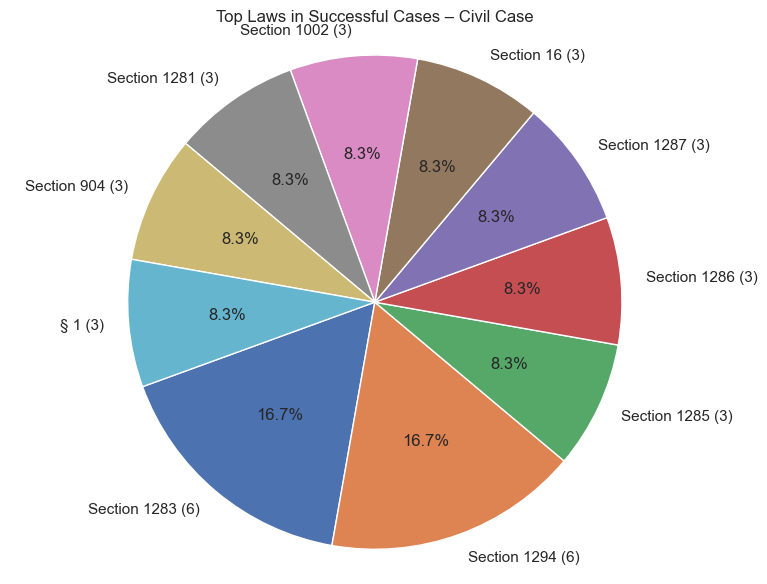

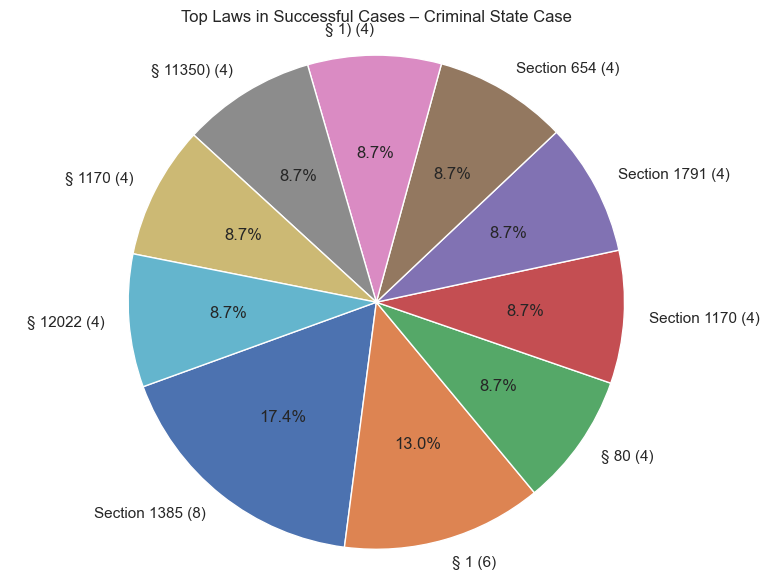

In [105]:
import re
import matplotlib.pyplot as plt
from collections import Counter

# === 1. Витягуємо базовий номер закону ===
def extract_base_number(law):
    match = re.search(r'(§|Section)\s?\d+[A-Za-z0-9\-()]*', law)
    return match.group(0).strip() if match else law

# === 2. Очистка ===
def clean_law_name(text):
    text = text.lower()
    text = re.sub(r'\b(see code|titled|title)\b', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    text = text.replace('section', 'Section').replace('§', '§')
    return text

# === 3. Комбінація номер + текст ===
def expand_laws_with_codes(law_list):
    if not isinstance(law_list, list):
        return []
    
    law_numbers = [law for law in law_list if re.search(r'\d', law)]
    law_texts = [law for law in law_list if not re.search(r'\d', law)]
    
    combined = [f"{num} {text}" for num in law_numbers for text in law_texts]
    cleaned_combined = [clean_law_name(law) for law in combined]
    return cleaned_combined

# === 4. Створюємо колонку expanded_laws ===
df_law_success['expanded_laws'] = df_law_success['law_list'].apply(expand_laws_with_codes)

# === 5. Побудова pie chart для кожного типу справи ===
SUCCESS_THRESHOLD = 0.6
case_types = df_law_success['case_type'].unique()

for case_type in case_types:
    subset = df_law_success[
        (df_law_success['case_type'] == case_type) &
        (df_law_success['avg_success_rate'] > SUCCESS_THRESHOLD)
    ]

    if subset.empty:
        continue

    # ⏬ Витягуємо базові номери з усіх законів
    all_laws = [extract_base_number(law) for laws in subset['expanded_laws'] for law in laws]

    # 📊 Частота
    law_counts = Counter(all_laws)
    top_laws = law_counts.most_common(10)

    if not top_laws:
        continue

    labels = [f"{law} ({count})" for law, count in top_laws]
    sizes = [count for _, count in top_laws]

    plt.figure(figsize=(8, 6))
    plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=200)
    plt.title(f"Top Laws in Successful Cases – {case_type}")
    plt.axis('equal')
    plt.tight_layout()
    plt.show()
    


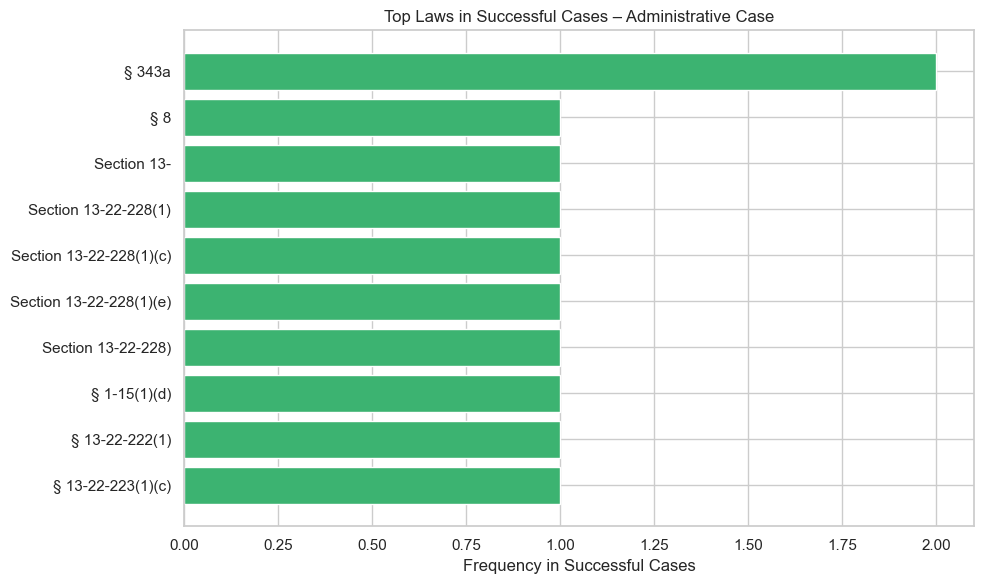

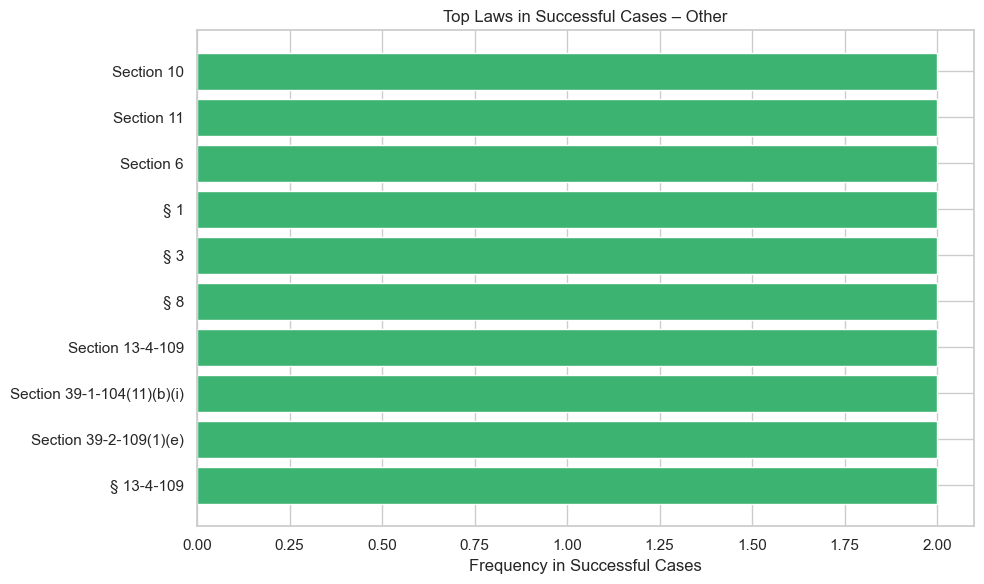

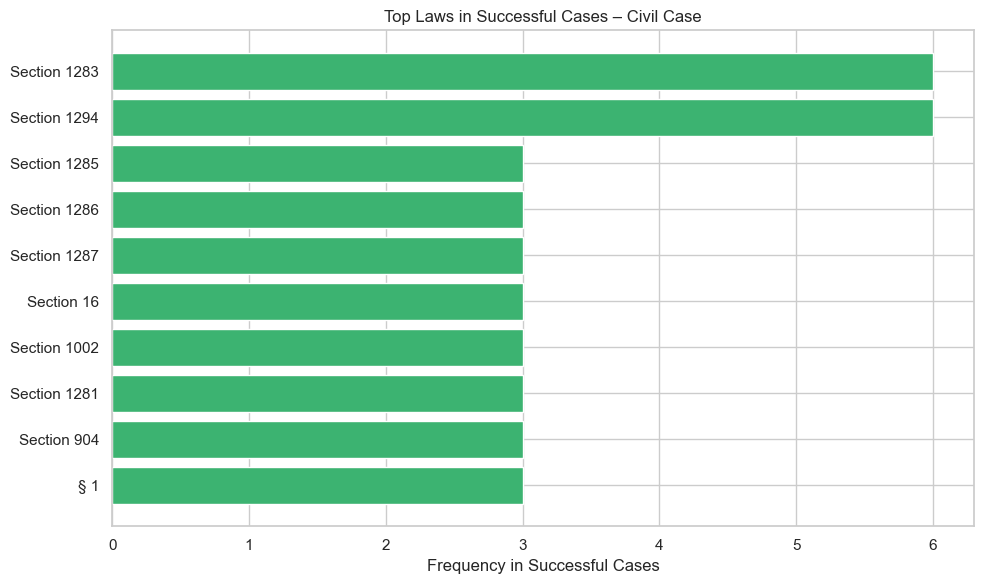

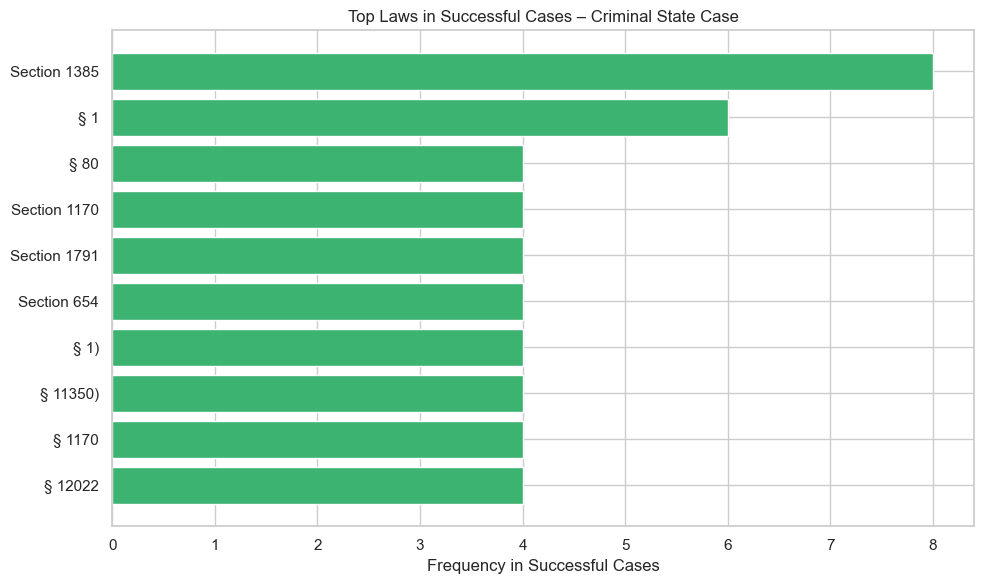

In [116]:
import re
import matplotlib.pyplot as plt
from collections import Counter

# === 1. Витягуємо базовий номер закону ===
def extract_base_number(law):
    match = re.search(r'(§|Section)\s?\d+[A-Za-z0-9\-()]*', law)
    return match.group(0).strip() if match else law

# === 2. Очистка ===
def clean_law_name(text):
    text = text.lower()
    text = re.sub(r'\b(see code|titled|title)\b', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    text = text.replace('section', 'Section').replace('§', '§')
    return text

# === 3. Комбінація номер + текст ===
def expand_laws_with_codes(law_list):
    if not isinstance(law_list, list):
        return []
    
    law_numbers = [law for law in law_list if re.search(r'\d', law)]
    law_texts = [law for law in law_list if not re.search(r'\d', law)]
    
    combined = [f"{num} {text}" for num in law_numbers for text in law_texts]
    cleaned_combined = [clean_law_name(law) for law in combined]
    return cleaned_combined

# === 4. Створюємо колонку expanded_laws ===
df_law_success['expanded_laws'] = df_law_success['law_list'].apply(expand_laws_with_codes)

# === 5. Побудова bar chart для кожного типу справи ===
SUCCESS_THRESHOLD = 0.6
case_types = df_law_success['case_type'].unique()

for case_type in case_types:
    subset = df_law_success[
        (df_law_success['case_type'] == case_type) &
        (df_law_success['avg_success_rate'] > SUCCESS_THRESHOLD)
    ]

    if subset.empty:
        continue

    # Витягуємо базові номери
    all_laws = [extract_base_number(law) for laws in subset['expanded_laws'] for law in laws]

    law_counts = Counter(all_laws)
    top_laws = law_counts.most_common(10)

    if not top_laws:
        continue

    laws, counts = zip(*top_laws)

    plt.figure(figsize=(10, 6))
    bars = plt.barh(laws, counts, color='mediumseagreen')
    plt.xlabel("Frequency in Successful Cases")
    plt.title(f"Top Laws in Successful Cases – {case_type}")
    plt.gca().invert_yaxis()  # Найпопулярніші — зверху

    # Додаємо значення до барів
    # for bar in bars:
    #     width = bar.get_width()
    #     plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
    #              f'{int(width)}', va='center')

    plt.tight_layout()
    plt.show()


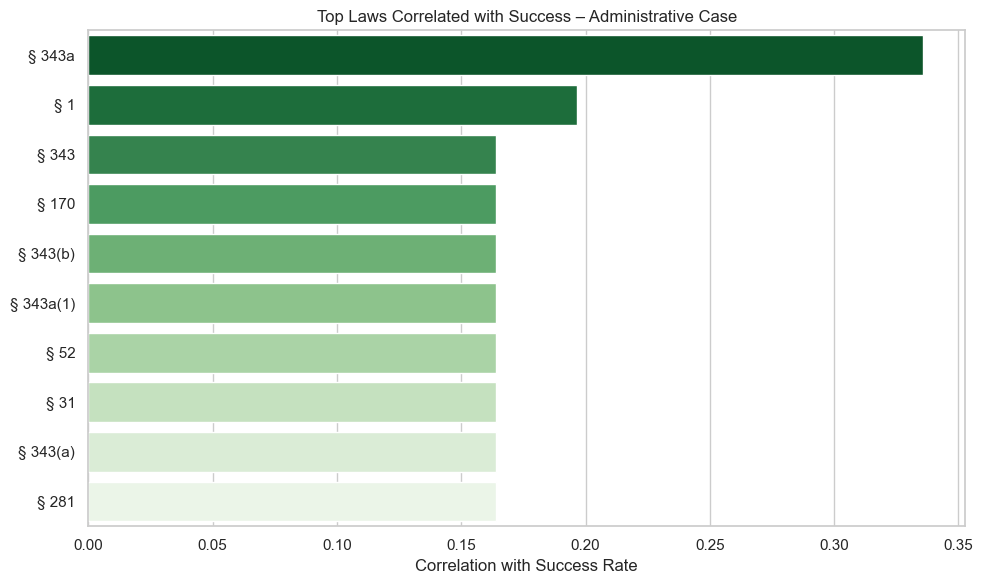

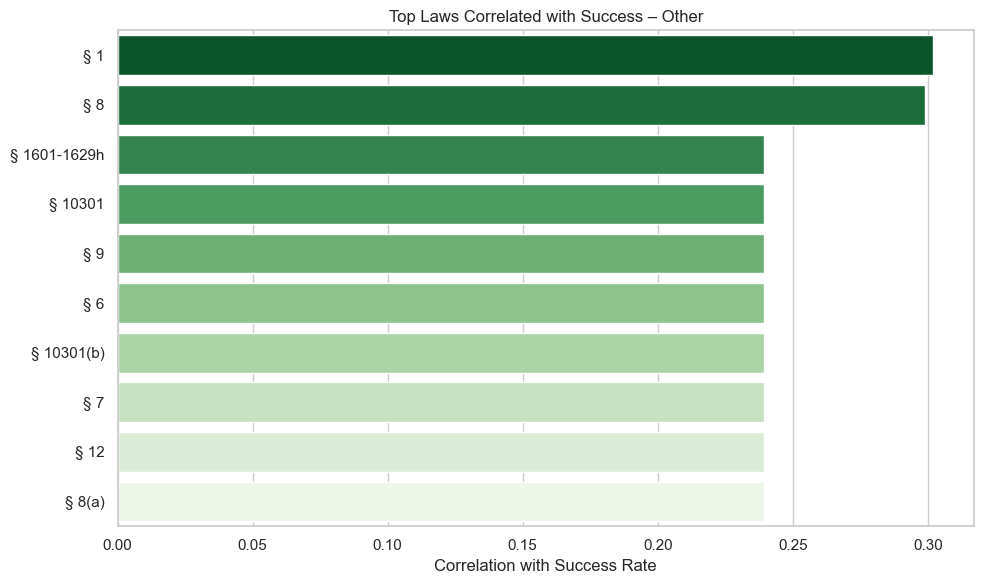

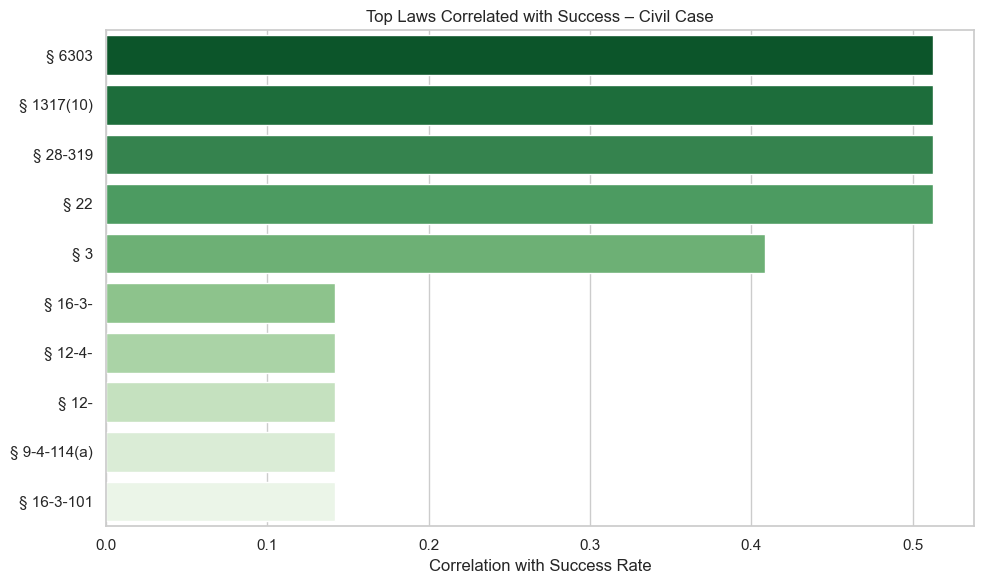

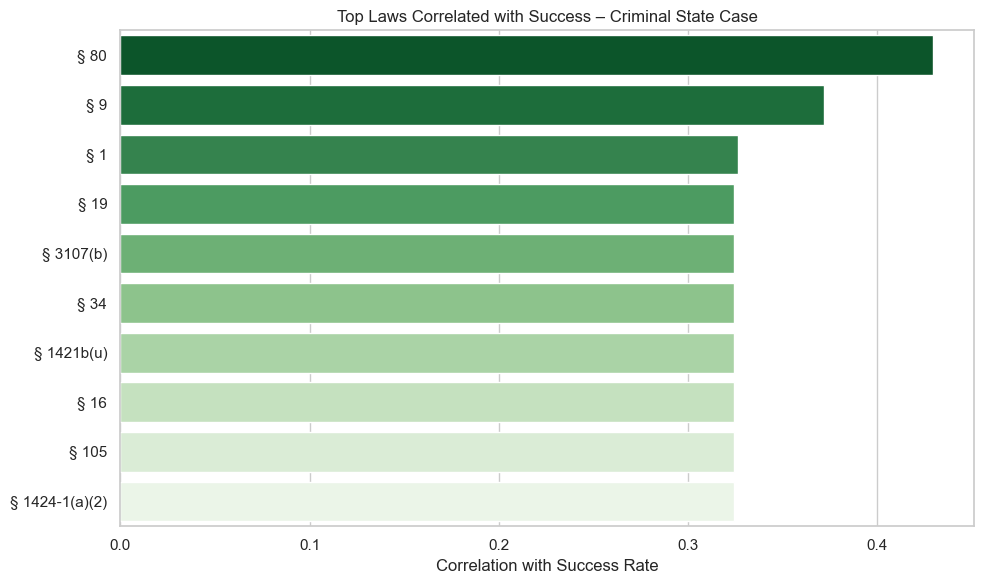

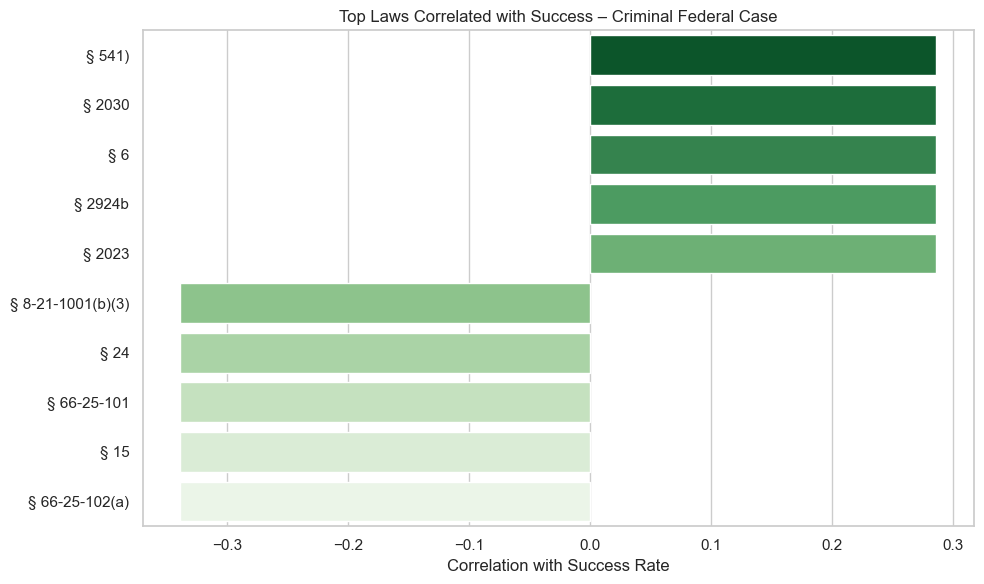

In [108]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

# === 1. Очистка назв закону ===
def clean_law_name(text):
    text = text.lower()
    text = re.sub(r'\b(see code|titled|title)\b', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    text = text.replace('section', 'Section').replace('§', '§')
    return text

# === 2. Комбінація номер + текст ===
def expand_laws_with_codes(law_list):
    if not isinstance(law_list, list):
        return []
    
    law_numbers = [law for law in law_list if re.search(r'\d', law)]
    law_texts = [law for law in law_list if not re.search(r'\d', law)]
    
    combined = [f"{num} {text}" for num in law_numbers for text in law_texts]
    cleaned_combined = [clean_law_name(law) for law in combined]
    return cleaned_combined

# === 3. Витяг базового номера закону ===
def extract_base_number(law):
    # Уніфікуємо "Section" до "§"
    law = re.sub(r'\bSection\b', '§', law, flags=re.IGNORECASE)
    # Витягуємо номер
    match = re.search(r'(§)\s?\d+[A-Za-z0-9\-()]*', law)
    return match.group(0).strip() if match else law


# === 4. Генерація колонок expanded_laws ===
df_law_success['expanded_laws'] = df_law_success['law_list'].apply(expand_laws_with_codes)

# === 5. Побудова графіку для кожного case_type ===
case_types = df_law_success['case_type'].unique()

for case_type in case_types:
    subset = df_law_success[df_law_success['case_type'] == case_type].copy()
    if subset.empty:
        continue

    # === One-hot encoding по expanded_laws
    mlb = MultiLabelBinarizer()
    law_features = mlb.fit_transform(subset['expanded_laws'])
    df_features = pd.DataFrame(law_features, columns=mlb.classes_)
    df_features['avg_success_rate'] = subset['avg_success_rate'].values

    # === Групування ознак по базовому номеру закону
    column_mapping = {col: extract_base_number(col) for col in df_features.columns if col != 'avg_success_rate'}
    grouped_features = {}

    for base_col in set(column_mapping.values()):
        matched_cols = [col for col, base in column_mapping.items() if base == base_col]
        grouped_features[base_col] = df_features[matched_cols].sum(axis=1)

    # === Побудова фінального DataFrame з avg_success_rate
    df_grouped = pd.DataFrame(grouped_features)
    df_grouped['avg_success_rate'] = df_features['avg_success_rate']

    # === Кореляція
    correlations = df_grouped.corr(numeric_only=True)['avg_success_rate'].drop('avg_success_rate')
    correlations = correlations.sort_values(ascending=False)
    top_laws = correlations.head(10)

    if top_laws.empty:
        continue

    # === Побудова графіку
    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_laws.values, y=top_laws.index, palette="Greens_r")
    plt.xlabel("Correlation with Success Rate")
    plt.ylabel("")  # Прибрати 'None' зліва
    plt.title(f"Top Laws Correlated with Success – {case_type}")
    plt.tight_layout()
    plt.show()
    